In [2]:
import sys
sys.path.insert(1, '/home/santolam/MyPythonLibrary/MAR-RECAP/libmar/')
import climbasis as climb
from climbasis import *
import domain as dom
import myplot
import numpy.ma as ma
from myplot import *
import obsinfo as obs
from obsinfo import *
from scipy.stats import pearsonr
import mar

In [3]:
iyr=1980
fyr=2024
domain='GRa'; domainM='GRq'
var='T2M';units='°C'

In [4]:
sourceData='/bettik/PROJECTS/pr-regional-climate/santolam/'
plotsDir='/home/santolam/RECAP/figures/'


In [5]:
model1='MAR'
res1=str('7kmx7km')
nx=ny=10

ds_TTZ_raw= xr.open_dataset(f'/bettik/PROJECTS/pr-regional-climate/santolam/MARout_post/{domainM}/spin2/work/monthly/'+
                           'TTZ_mon_MARv3.14_ER5_spin2_'+domainM+'_1980-2024.nc')['TTZ'][:,0,:,:] ## montlhy mean
ds_TTZ = ds_TTZ_raw.rename({'TIME': 'time'})
#units=ds_TTZ.units

ds1=ds_TTZ[:,ny:-ny,nx:-nx].sel(time=slice(str(iyr), str(fyr)))


In [6]:
ds_grid= xr.open_dataset('/home/santolam/NST.2014.01.01.00.GRi.nc')
LONS=ds_grid.LON[ny:-ny,nx:-nx].values
LATS=ds_grid.LAT[ny:-ny,nx:-nx].values
dsSH=ds_grid.SH[ny:-ny,nx:-nx]
dsICE=ds_grid.ICE[ny:-ny,nx:-nx]

In [7]:
field1_SH= dsSH.assign_coords({
    'lat': (('y', 'x'), LATS),
    'lon': (('y', 'x'),LONS)
})

In [8]:
field1=ds1.assign_coords({
    'lat': (('Y', 'X'), LATS),
    'lon': (('Y', 'X'),LONS)
})
#field1=field1.rename({"Y":"y","X":"x"})

In [9]:
print(field1_SH.shape,field1.shape)

(62, 96) (540, 62, 96)


In [10]:
###Select the real domain
latS=field1.lat.min(); latN=field1.lat.max()
lonW=field1.lon.min(); lonE=field1.lon.max()
print(latS.values,latN.values,lonW.values,lonE.values)

3.685060501098633e+01 40.75126647949219 68.39894104003906 76.28392028808594


In [11]:
model3='era5-land'
res3=str('0.1°x0.1°')

ds3_raw= xr.open_dataset(f'/bettik/PROJECTS/pr-regional-climate/santolam/era5-land/'+
                         't2m_mon.era5-land_1980-2024_HMA_01x01.nc')['t2m']
ds3=ds3_raw.rename({'valid_time': 'time','latitude':'lat','longitude':'lon'})
ds3=ds3.sel(time=slice(str(iyr),str(fyr)))-273.15

field3=ds3.sel(lat=slice(latN,latS),lon=slice(lonW,lonE))


In [12]:
ds3_SH=xr.open_dataset('/bettik/PROJECTS/pr-regional-climate/santolam/gmted/'+
                       'gmted_on_t2m_era5-land_corrected.nc')['elevation']
ds3_SH=ds3_SH.rename({'latitude':'lat','longitude':'lon'})
field3_SH=ds3_SH.sel(lat=slice(latN,latS),lon=slice(lonW,lonE))


In [13]:
print(field3_SH.shape,field3.shape)

(39, 79) (540, 39, 79)


In [14]:
print(field3.shape,field3_SH.shape)

(540, 39, 79) (39, 79)


In [15]:
model4='era5'
res4=str('0.25°x0.25°')
ds4_raw= xr.open_dataset('/bettik/PROJECTS/pr-regional-climate/santolam/era5/'
                         +'t2m.mon_era5_1940-2025_HMA_025x025.nc')['t2m']
ds4=ds4_raw-273.15
ds4=ds4_raw.rename({'valid_time': 'time','latitude':'lat','longitude':'lon'})
ds4=ds4.sel(time=slice(str(iyr),str(fyr)))-273.15

field4=ds4.sel(lat=slice(latN,latS),lon=slice(lonW,lonE))


In [16]:
ds4_SH=xr.open_dataset('/bettik/PROJECTS/pr-regional-climate/santolam/gmted/gmted_on_era5_grid.nc')['elevation']
ds4_SH=ds4_SH.rename({'latitude':'lat','longitude':'lon'})

field4_SH=ds4_SH.sel(lat=slice(latN,latS),lon=slice(lonW,lonE))


In [17]:
#print(field4.shape,field4_SH.shape)

In [18]:
#print(field4.lat[0:2],field3.lat[0:2])

In [19]:
model5='cru'
res5=str('0.5°x0.5°')

fileName5='cru_ts4.05.1901.2020.tmp.dat.nc'
ds5_raw= xr.open_dataset('/bettik/PROJECTS/pr-regional-climate/santolam/'+model5+'/'+fileName5)['tmp']
ds5=dom.reversing_lat(ds5_raw)
field5=ds5.sel(lat=slice(latN,latS),lon=slice(lonW,lonE))
field5=field5.sel(time=slice(str(iyr),str(2020)))

In [20]:
#field5

In [21]:
ds5_SH_raw=xr.open_dataset('/bettik/PROJECTS/pr-regional-climate/santolam/gmted/gmted_on_cru_hma_grid.nc')['elevation']
ds5_SH=dom.reversing_lat(ds5_SH_raw)
field5_SH=ds5_SH.sel(lat=slice(latN,latS),lon=slice(lonW,lonE))

In [22]:
#field5_SH[:,:].plot()

In [23]:
model7='HARv2'
res7='10kmx10km'
#variable='prcp'
fileName7='HARv2_mon_d10km_d_2d_t2_1980-2023.nc'
ds7_raw0= xr.open_dataset('/bettik/PROJECTS/pr-regional-climate/santolam/'+'/'+model7+'/'+fileName7)['t2']
ds7=ds7_raw0 - 273.15

def xy_sel_dom(ds,latS,latN,lonW,lonE):
    #latS,latN,lonW,lonE,latlim,lonlim=dom.coord_domain(domain)
    lat_str = ''
    lon_str = ''
    other_dims_str = []
    for dim in ds.coords:
        print(dim)
        if dim in ['lat', 'latitude','LON']:
            lat_str = dim
        elif dim in ['lon', 'longitude','LAT']:
            lon_str = dim
        else:
            other_dims_str.append(dim)
    mask = (
        (latS < ds[lat_str]) & ( ds[lat_str] < latN) 
    & (lonW < ds[lon_str]) & ( ds[lon_str] < lonE)
    )
    field_dom=ds.where(mask,drop=True)
    return field_dom

# Apply mask (non-NaN where the condition is True)
#hgt_subset = hgt.where(mask, drop=True)
field7=xy_sel_dom(ds7.sel(time=slice(str(iyr),str(2023))),latS,latN,lonW,lonE)

time
lon
lat
west_east
south_north


In [24]:
#field7[0,:,:].plot()

In [25]:
fileName7_grF='HARv2_d10km_static_hgt.nc'
ds7_grM= xr.open_dataset(sourceData+'/'+model7+'/'+fileName7_grF)
ds7SH=ds7_grM['hgt'][0,:,:]
#dsSH
field7_SH=xy_sel_dom(ds7SH,latS,latN,lonW,lonE)


time
west_east
south_north
lon
lat


In [26]:

## SAME ANALYSIS BUT FOR multiple data sets(at the same time): lists

dsList=[field1,
        field3,field4,field5,
        field7]
modelList=[model1,
           model3,model4,model5,
           model7]
resList=[res1,
         res3,res4,res5,
         res7]
nameList=list(zip(modelList,resList))

In [27]:
nameList

[('MAR', '7kmx7km'),
 ('era5-land', '0.1°x0.1°'),
 ('era5', '0.25°x0.25°'),
 ('cru', '0.5°x0.5°'),
 ('HARv2', '10kmx10km')]

In [28]:
def compute_seasonal_means(field, season_months):
    """Compute seasonal and annual means (per year)."""

    month = field['time'].dt.month
    year = field['time'].dt.year
    year_shifted = xr.where(month == 12, year + 1, year)  # Dec → next year

    results = []

    # ---- Seasonal means ----
    for season, months in season_months.items():
        vals = field.sel(time=month.isin(months))
        vals = vals.assign_coords(year=year_shifted.sel(time=vals.time))
        vals_mean = vals.groupby('year').mean('time', skipna=True)
        vals_mean = vals_mean.expand_dims({'season': [season]})
        results.append(vals_mean)

    # ---- Annual mean ----
    ann = field.assign_coords(year=year)
    ann_mean = ann.groupby('year').mean('time', skipna=True)
    ann_mean = ann_mean.expand_dims({'season': ['ANN']})
    results.append(ann_mean)

    return xr.concat(results, dim='season')

seasonList = ['DJFM', 'AM', 'JJAS', 'ON','ANN']
season_months = {
    'DJFM': [12, 1, 2, 3],
    'AM': [4, 5],
    'JJAS': [6, 7, 8, 9],
    'ON': [10, 11]
}

In [30]:
field1_season_all = compute_seasonal_means(field1, season_months)
field3_season_all = compute_seasonal_means(field3, season_months)
field4_season_all = compute_seasonal_means(field4, season_months)
field5_season_all = compute_seasonal_means(field5, season_months)
field7_season_all = compute_seasonal_means(field7, season_months)


In [31]:
field1_season_all

<xarray.DataArray 'TTZ' (season: 5, year: 46, Y: 62, X: 96)>
array([[[[ 18.597818  ,  18.555609  ,  18.524572  , ...,  19.297924  ,
           19.530203  ,  20.102829  ],
         [ 18.530403  ,  18.47069   ,  18.416328  , ...,  18.997385  ,
           19.140173  ,  19.581348  ],
         [ 18.488485  ,  18.437288  ,  18.371979  , ...,  18.788363  ,
           18.73352   ,  18.852747  ],
         ...,
         [-18.947939  , -18.040339  , -15.957603  , ..., -12.984238  ,
          -13.44662   , -15.330002  ],
         [-18.55365   , -16.781721  , -15.500157  , ..., -12.395095  ,
          -12.790288  , -13.428857  ],
         [-16.920506  , -15.642318  , -14.943851  , ..., -12.091422  ,
          -12.41685   , -12.59868   ]],

        [[ 17.717957  ,  17.581512  ,  17.573929  , ...,  18.747314  ,
           19.09068   ,  19.79778   ],
         [ 17.509998  ,  17.319044  ,  17.308296  , ...,  18.426828  ,
           18.718462  ,  19.384012  ],
         [ 17.459517  ,  17.28673   ,  17.26709   , ...,  18.270031  ,
           18.369453  ,  18.767256  ],
...
         [ -6.5814743 ,  -5.596525  ,  -4.5512066 , ...,  -2.4669702 ,
           -2.7152274 ,  -2.8482792 ],
         [ -6.7489867 ,  -5.4665756 ,  -4.5914288 , ...,  -2.2134001 ,
           -2.389446  ,  -2.4584835 ],
         [ -6.36182   ,  -5.661314  ,  -4.6455507 , ...,  -1.9243876 ,
           -2.1512277 ,  -2.1705973 ]],

        [[         nan,          nan,          nan, ...,          nan,
                   nan,          nan],
         [         nan,          nan,          nan, ...,          nan,
                   nan,          nan],
         [         nan,          nan,          nan, ...,          nan,
                   nan,          nan],
         ...,
         [         nan,          nan,          nan, ...,          nan,
                   nan,          nan],
         [         nan,          nan,          nan, ...,          nan,
                   nan,          nan],
         [         nan,          nan,          nan, ...,          nan,
                   nan,          nan]]]], dtype=float32)
Coordinates:
  * year     (year) int64 1980 1981 1982 1983 1984 ... 2021 2022 2023 2024 2025
  * season   (season) <U4 'DJFM' 'AM' 'JJAS' 'ON' 'ANN'
  * X        (X) float32 -420.0 -413.0 -406.0 -399.0 ... 224.0 231.0 238.0 245.0
  * Y        (Y) float32 -119.0 -112.0 -105.0 -98.0 ... 287.0 294.0 301.0 308.0
    ZTQLEV   float32 2.0
    lat      (Y, X) float32 36.85 36.86 36.86 36.86 ... 40.69 40.69 40.69 40.68
    lon      (Y, X) float32 68.6 68.68 68.76 68.84 ... 76.04 76.12 76.2 76.28

DJFM


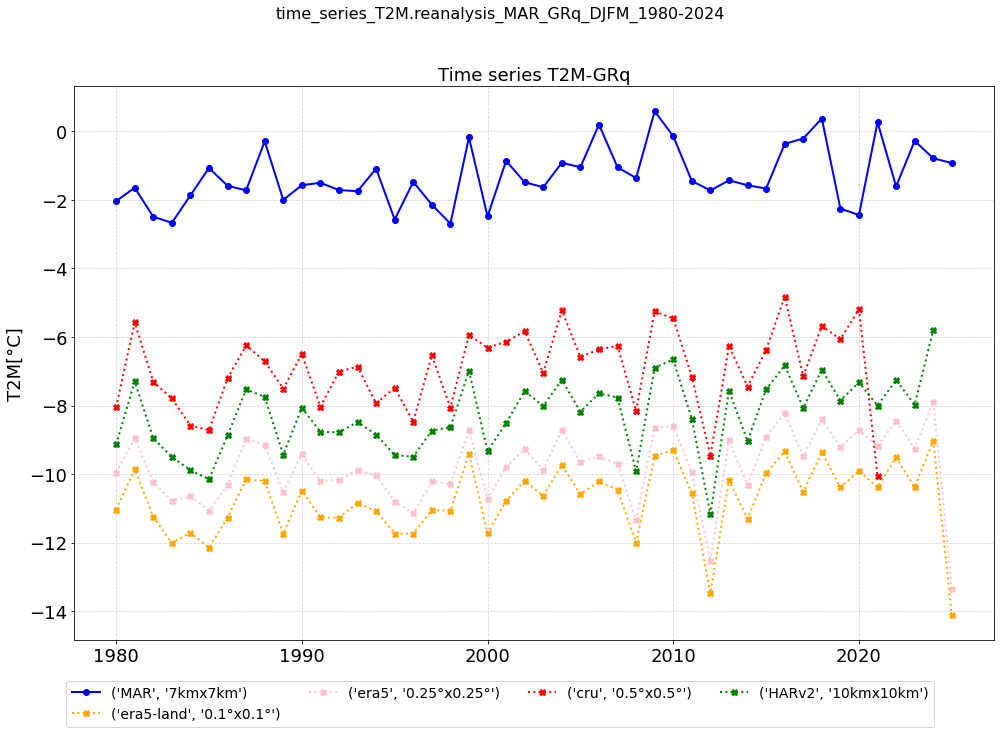

/home/santolam/RECAP/figures/time_series_T2M.reanalysis_MAR_GRq_DJFM_1980-2024.png
[-1.3101575374603271, -10.759398460388184, -9.788951873779297, -6.925187587738037, -8.273088455200195]
[0.8450863361358643, 1.0408281087875366, 1.070476770401001, 1.1759669780731201, 1.0654131174087524]


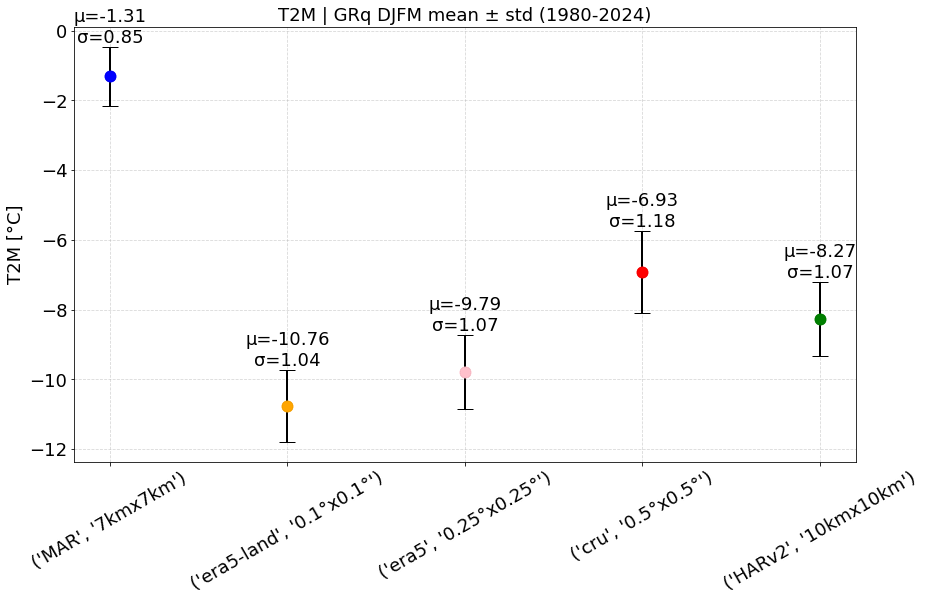

/home/santolam/RECAP/figures/mean_stddev_T2M.reanalysis_MAR_GRq_DJFM_1980-2024.png


In [30]:
season=seasonList[0]
print(season)
field1_season = field1_season_all.sel(season=season)
field3_season = field3_season_all.sel(season=season)
field4_season = field4_season_all.sel(season=season)
field5_season = field5_season_all.sel(season=season)
#field6_season = field6_season_all.sel(season=season)
field7_season = field7_season_all.sel(season=season)

# Then apply it like this:
ts_mean_vals_field1 = field1_season.mean(dim=['X', 'Y'])
ts_mean_vals_field3 = field3_season.mean(dim= ['lon', 'lat'])
ts_mean_vals_field4= field4_season.mean(dim=['lon', 'lat'])
ts_mean_vals_field5= field5_season.mean(dim= ['lon', 'lat'])
#ts_mean_vals_field6= field6_season.mean(dim=['lon', 'lat'])
ts_mean_vals_field7 = field7_season.mean(dim=  ['south_north', 'west_east'])

colorList=['b','orange', 'pink', 'red', 'green','black']
markerList=['o','X','X','X','X','X','X']#

plotname=f'time_series_{var}.reanalysis_MAR_{domainM}_{season}_{str(iyr)}-{str(fyr)}'

colors = colorList


fig, ax= plt.subplots(figsize=(14, 10), sharex=False, sharey=False)

# Plot one line per dataset
ax.plot(ts_mean_vals_field1.year, ts_mean_vals_field1.values, 'o', linestyle='-',label=nameList[0], color=colors[0], linewidth=2)
ax.plot(ts_mean_vals_field3.year, ts_mean_vals_field3.values,marker=markerList[1], linestyle=':',label=nameList[1], color=colors[1], linewidth=2)
ax.plot(ts_mean_vals_field4.year, ts_mean_vals_field4.values,marker=markerList[2],linestyle=':',label=nameList[2], color=colors[2], linewidth=2)
ax.plot(ts_mean_vals_field5.year,ts_mean_vals_field5.values, marker=markerList[3],linestyle=':',label=nameList[3], color=colors[3], linewidth=2)
#ax.plot(ts_mean_vals_field6.year ,ts_mean_vals_field6.values,marker=markerList[4],linestyle='-',label=nameList[4], color=colors[4], linewidth=2)    
ax.plot(ts_mean_vals_field7.year,ts_mean_vals_field7.values, marker=markerList[5],linestyle=':',label=nameList[4], color=colors[4], linewidth=2)

ax.set_title(f'Time series {var}-{domainM}', fontsize=18)
#ax.set_xticks(months)
ax.set_ylabel(f'{var}[{units}]', fontsize=18)
#years=ac_mean_vals_field1[0].year.values
#xticks = years[::2]
ax.tick_params(axis='y', labelsize=18)
ax.tick_params(axis='x', labelsize=18)

ax.grid(True, linestyle='--', alpha=0.5)

# Axis labels and legend
fig.suptitle(plotname, fontsize=16)
#fig.supxlabel('Month', fontsize=14)
#fig.supylabel('Snow Height [m]', fontsize=14)

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc='lower center',
    bbox_to_anchor=(0.5, -0.03),
    ncol=4,
    fontsize=14,
    frameon=True
)

# Adjust layout and save with full legend
plt.tight_layout(rect=[0, 0.05, 1, 0.95])
#plt.savefig(plotsDir + 'monthly_snowheight_by_elevation.png', , dpi=300)

# Save figure (including legend outside)
plt.savefig(plotsDir+plotname+'.png', bbox_inches='tight')
plt.show()
print(plotsDir+plotname+'.png')


datasets = [
    ts_mean_vals_field1,
    ts_mean_vals_field3,
    ts_mean_vals_field4,
    ts_mean_vals_field5,
    #ts_mean_vals_field6,
    ts_mean_vals_field7,
]

dataset_names = nameList  # same order
colors = colorList

means = [ds.mean(dim='year').values.item() for ds in datasets]
stds  = [ds.std(dim='year').values.item() for ds in datasets]
print(means)
print(stds)
plotname=f'mean_stddev_{var}.reanalysis_MAR_{domainM}_{season}_{str(iyr)}-{str(fyr)}'

fig, ax = plt.subplots(figsize=(14, 8))

x = np.arange(len(dataset_names))

ax.errorbar(
    x, means, yerr=stds,
    fmt='o',
    capsize=8,
    markersize=10,
    linewidth=2,
    color='black'
)

# Color individual points
for xi, mu, color in zip(x, means, colors):
    ax.scatter(xi, mu, color=color, s=120, zorder=3)

ax.set_xticks(x)
ax.set_xticklabels(dataset_names, rotation=30,fontsize=18)
ax.set_ylabel(f'{var} [{units}]',fontsize=18)
ax.tick_params(axis='y', labelsize=18)
ax.tick_params(axis='x', labelsize=18)
#ax.set_ylim(0,70)
ax.set_title(f'{var} | {domainM} {season} mean ± std ({iyr}-{fyr})',fontsize=18)
ax.grid(True, linestyle='--', alpha=0.5)

# Annotate
for xi, mu, sigma in zip(x, means, stds):
    ax.text(
        xi, mu + sigma,
        f'μ={mu:.2f}\nσ={sigma:.2f}',
        ha='center',
        va='bottom',
        fontsize=18
    )

# Save figure (including legend outside)
plt.savefig(plotsDir+plotname+'.png', bbox_inches='tight')
plt.show()
print(plotsDir+plotname+'.png')

AM


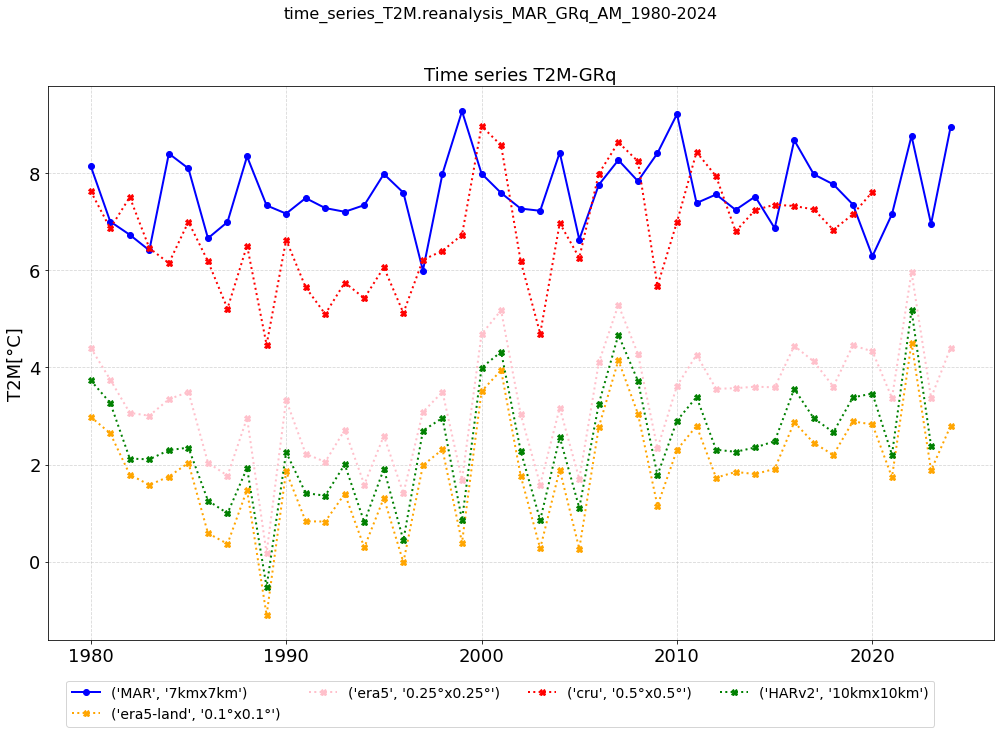

/home/santolam/RECAP/figures/time_series_T2M.reanalysis_MAR_GRq_AM_1980-2024.png
[7.615366458892822, 1.8807586431503296, 3.2855546474456787, 6.7391581535339355, 2.415480613708496]
[0.7493178248405457, 1.1386667490005493, 1.152952790260315, 1.0828860998153687, 1.14449143409729]


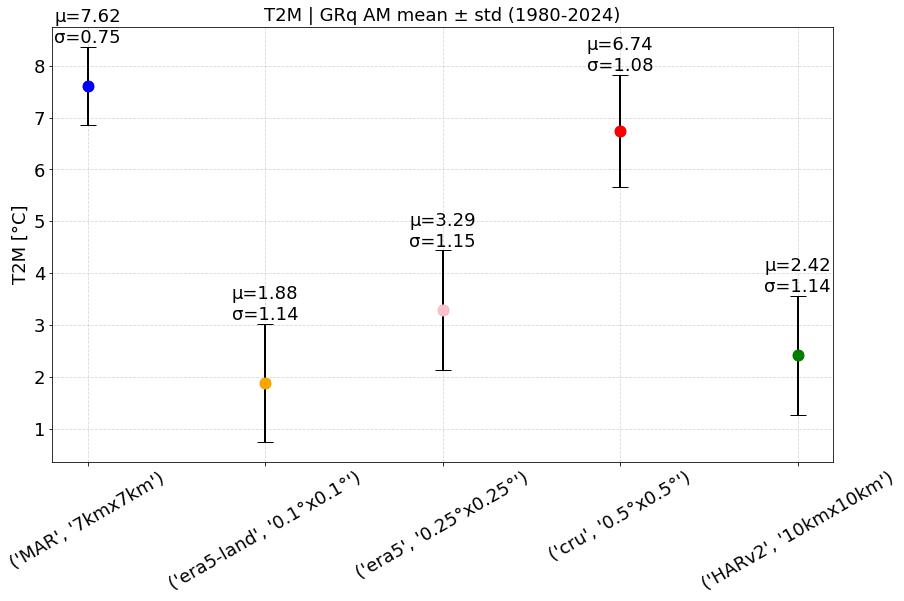

/home/santolam/RECAP/figures/mean_stddev_T2M.reanalysis_MAR_GRq_AM_1980-2024.png


In [31]:
season=seasonList[1]
print(season)
field1_season = field1_season_all.sel(season=season)
field3_season = field3_season_all.sel(season=season)
field4_season = field4_season_all.sel(season=season)
field5_season = field5_season_all.sel(season=season)
#field6_season = field6_season_all.sel(season=season)
field7_season = field7_season_all.sel(season=season)

# Then apply it like this:
ts_mean_vals_field1 = field1_season.mean(dim=['X', 'Y'])
ts_mean_vals_field3 = field3_season.mean(dim= ['lon', 'lat'])
ts_mean_vals_field4= field4_season.mean(dim=['lon', 'lat'])
ts_mean_vals_field5= field5_season.mean(dim= ['lon', 'lat'])
#ts_mean_vals_field6= field6_season.mean(dim=['lon', 'lat'])
ts_mean_vals_field7 = field7_season.mean(dim=  ['south_north', 'west_east'])

colorList=['b','orange', 'pink', 'red', 'green','black']
markerList=['o','X','X','X','X','X','X']#

plotname=f'time_series_{var}.reanalysis_MAR_{domainM}_{season}_{str(iyr)}-{str(fyr)}'

colors = colorList


fig, ax= plt.subplots(figsize=(14, 10), sharex=False, sharey=False)

# Plot one line per dataset
ax.plot(ts_mean_vals_field1.year, ts_mean_vals_field1.values, 'o', linestyle='-',label=nameList[0], color=colors[0], linewidth=2)
ax.plot(ts_mean_vals_field3.year, ts_mean_vals_field3.values,marker=markerList[1], linestyle=':',label=nameList[1], color=colors[1], linewidth=2)
ax.plot(ts_mean_vals_field4.year, ts_mean_vals_field4.values,marker=markerList[2],linestyle=':',label=nameList[2], color=colors[2], linewidth=2)
ax.plot(ts_mean_vals_field5.year,ts_mean_vals_field5.values, marker=markerList[3],linestyle=':',label=nameList[3], color=colors[3], linewidth=2)
#ax.plot(ts_mean_vals_field6.year ,ts_mean_vals_field6.values,marker=markerList[4],linestyle='-',label=nameList[4], color=colors[4], linewidth=2)    
ax.plot(ts_mean_vals_field7.year,ts_mean_vals_field7.values, marker=markerList[5],linestyle=':',label=nameList[4], color=colors[4], linewidth=2)

ax.set_title(f'Time series {var}-{domainM}', fontsize=18)
#ax.set_xticks(months)
ax.set_ylabel(f'{var}[{units}]', fontsize=18)
#years=ac_mean_vals_field1[0].year.values
#xticks = years[::2]
ax.tick_params(axis='y', labelsize=18)
ax.tick_params(axis='x', labelsize=18)

ax.grid(True, linestyle='--', alpha=0.5)

# Axis labels and legend
fig.suptitle(plotname, fontsize=16)
#fig.supxlabel('Month', fontsize=14)
#fig.supylabel('Snow Height [m]', fontsize=14)

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc='lower center',
    bbox_to_anchor=(0.5, -0.03),
    ncol=4,
    fontsize=14,
    frameon=True
)

# Adjust layout and save with full legend
plt.tight_layout(rect=[0, 0.05, 1, 0.95])
#plt.savefig(plotsDir + 'monthly_snowheight_by_elevation.png', , dpi=300)

# Save figure (including legend outside)
plt.savefig(plotsDir+plotname+'.png', bbox_inches='tight')
plt.show()
print(plotsDir+plotname+'.png')


datasets = [
    ts_mean_vals_field1,
    ts_mean_vals_field3,
    ts_mean_vals_field4,
    ts_mean_vals_field5,
    #ts_mean_vals_field6,
    ts_mean_vals_field7,
]

dataset_names = nameList  # same order
colors = colorList

means = [ds.mean(dim='year').values.item() for ds in datasets]
stds  = [ds.std(dim='year').values.item() for ds in datasets]
print(means)
print(stds)
plotname=f'mean_stddev_{var}.reanalysis_MAR_{domainM}_{season}_{str(iyr)}-{str(fyr)}'

fig, ax = plt.subplots(figsize=(14, 8))

x = np.arange(len(dataset_names))

ax.errorbar(
    x, means, yerr=stds,
    fmt='o',
    capsize=8,
    markersize=10,
    linewidth=2,
    color='black'
)

# Color individual points
for xi, mu, color in zip(x, means, colors):
    ax.scatter(xi, mu, color=color, s=120, zorder=3)

ax.set_xticks(x)
ax.set_xticklabels(dataset_names, rotation=30,fontsize=18)
ax.set_ylabel(f'{var} [{units}]',fontsize=18)
ax.tick_params(axis='y', labelsize=18)
ax.tick_params(axis='x', labelsize=18)
#ax.set_ylim(0,70)
ax.set_title(f'{var} | {domainM} {season} mean ± std ({iyr}-{fyr})',fontsize=18)
ax.grid(True, linestyle='--', alpha=0.5)

# Annotate
for xi, mu, sigma in zip(x, means, stds):
    ax.text(
        xi, mu + sigma,
        f'μ={mu:.2f}\nσ={sigma:.2f}',
        ha='center',
        va='bottom',
        fontsize=18
    )

# Save figure (including legend outside)
plt.savefig(plotsDir+plotname+'.png', bbox_inches='tight')
plt.show()
print(plotsDir+plotname+'.png')

JJAS


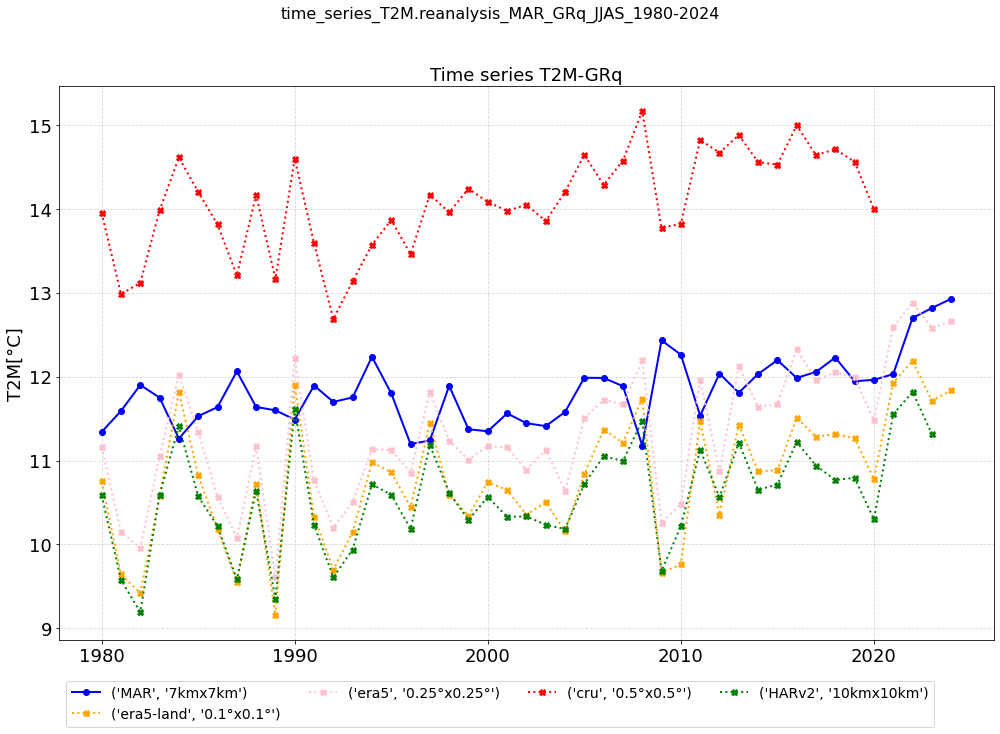

/home/santolam/RECAP/figures/time_series_T2M.reanalysis_MAR_GRq_JJAS_1980-2024.png
[11.827322959899902, 10.781538009643555, 11.323827743530273, 14.082208633422852, 10.577994346618652]
[0.4069209694862366, 0.7414193749427795, 0.783467710018158, 0.5843706727027893, 0.6111920475959778]


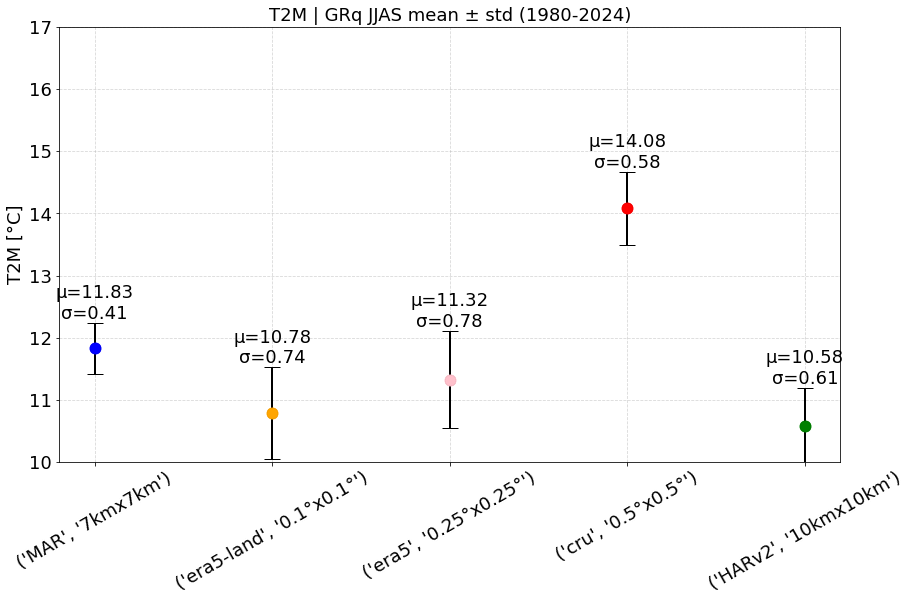

/home/santolam/RECAP/figures/mean_stddev_T2M.reanalysis_MAR_GRq_JJAS_1980-2024.png


In [32]:
season=seasonList[2]
print(season)
field1_season = field1_season_all.sel(season=season)
field3_season = field3_season_all.sel(season=season)
field4_season = field4_season_all.sel(season=season)
field5_season = field5_season_all.sel(season=season)
#field6_season = field6_season_all.sel(season=season)
field7_season = field7_season_all.sel(season=season)

# Then apply it like this:
ts_mean_vals_field1 = field1_season.mean(dim=['X', 'Y'])
ts_mean_vals_field3 = field3_season.mean(dim= ['lon', 'lat'])
ts_mean_vals_field4= field4_season.mean(dim=['lon', 'lat'])
ts_mean_vals_field5= field5_season.mean(dim= ['lon', 'lat'])
#ts_mean_vals_field6= field6_season.mean(dim=['lon', 'lat'])
ts_mean_vals_field7 = field7_season.mean(dim=  ['south_north', 'west_east'])

colorList=['b','orange', 'pink', 'red', 'green','black']
markerList=['o','X','X','X','X','X','X']#

plotname=f'time_series_{var}.reanalysis_MAR_{domainM}_{season}_{str(iyr)}-{str(fyr)}'

colors = colorList


fig, ax= plt.subplots(figsize=(14, 10), sharex=False, sharey=False)

# Plot one line per dataset
ax.plot(ts_mean_vals_field1.year, ts_mean_vals_field1.values, 'o', linestyle='-',label=nameList[0], color=colors[0], linewidth=2)
ax.plot(ts_mean_vals_field3.year, ts_mean_vals_field3.values,marker=markerList[1], linestyle=':',label=nameList[1], color=colors[1], linewidth=2)
ax.plot(ts_mean_vals_field4.year, ts_mean_vals_field4.values,marker=markerList[2],linestyle=':',label=nameList[2], color=colors[2], linewidth=2)
ax.plot(ts_mean_vals_field5.year,ts_mean_vals_field5.values, marker=markerList[3],linestyle=':',label=nameList[3], color=colors[3], linewidth=2)
#ax.plot(ts_mean_vals_field6.year ,ts_mean_vals_field6.values,marker=markerList[4],linestyle='-',label=nameList[4], color=colors[4], linewidth=2)    
ax.plot(ts_mean_vals_field7.year,ts_mean_vals_field7.values, marker=markerList[5],linestyle=':',label=nameList[4], color=colors[4], linewidth=2)

ax.set_title(f'Time series {var}-{domainM}', fontsize=18)
#ax.set_xticks(months)
ax.set_ylabel(f'{var}[{units}]', fontsize=18)
#years=ac_mean_vals_field1[0].year.values
#xticks = years[::2]
ax.tick_params(axis='y', labelsize=18)
ax.tick_params(axis='x', labelsize=18)

ax.grid(True, linestyle='--', alpha=0.5)

# Axis labels and legend
fig.suptitle(plotname, fontsize=16)
#fig.supxlabel('Month', fontsize=14)
#fig.supylabel('Snow Height [m]', fontsize=14)

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc='lower center',
    bbox_to_anchor=(0.5, -0.03),
    ncol=4,
    fontsize=14,
    frameon=True
)

# Adjust layout and save with full legend
plt.tight_layout(rect=[0, 0.05, 1, 0.95])
#plt.savefig(plotsDir + 'monthly_snowheight_by_elevation.png', , dpi=300)

# Save figure (including legend outside)
plt.savefig(plotsDir+plotname+'.png', bbox_inches='tight')
plt.show()
print(plotsDir+plotname+'.png')


datasets = [
    ts_mean_vals_field1,
    ts_mean_vals_field3,
    ts_mean_vals_field4,
    ts_mean_vals_field5,
    #ts_mean_vals_field6,
    ts_mean_vals_field7,
]

dataset_names = nameList  # same order
colors = colorList

means = [ds.mean(dim='year').values.item() for ds in datasets]
stds  = [ds.std(dim='year').values.item() for ds in datasets]
print(means)
print(stds)
plotname=f'mean_stddev_{var}.reanalysis_MAR_{domainM}_{season}_{str(iyr)}-{str(fyr)}'

fig, ax = plt.subplots(figsize=(14, 8))

x = np.arange(len(dataset_names))

ax.errorbar(
    x, means, yerr=stds,
    fmt='o',
    capsize=8,
    markersize=10,
    linewidth=2,
    color='black'
)

# Color individual points
for xi, mu, color in zip(x, means, colors):
    ax.scatter(xi, mu, color=color, s=120, zorder=3)

ax.set_xticks(x)
ax.set_xticklabels(dataset_names, rotation=30,fontsize=18)
ax.set_ylabel(f'{var} [{units}]',fontsize=18)
ax.tick_params(axis='y', labelsize=18)
ax.tick_params(axis='x', labelsize=18)
ax.set_ylim(10,17)
ax.set_title(f'{var} | {domainM} {season} mean ± std ({iyr}-{fyr})',fontsize=18)
ax.grid(True, linestyle='--', alpha=0.5)

# Annotate
for xi, mu, sigma in zip(x, means, stds):
    ax.text(
        xi, mu + sigma,
        f'μ={mu:.2f}\nσ={sigma:.2f}',
        ha='center',
        va='bottom',
        fontsize=18
    )

# Save figure (including legend outside)
plt.savefig(plotsDir+plotname+'.png', bbox_inches='tight')
plt.show()
print(plotsDir+plotname+'.png')

ON


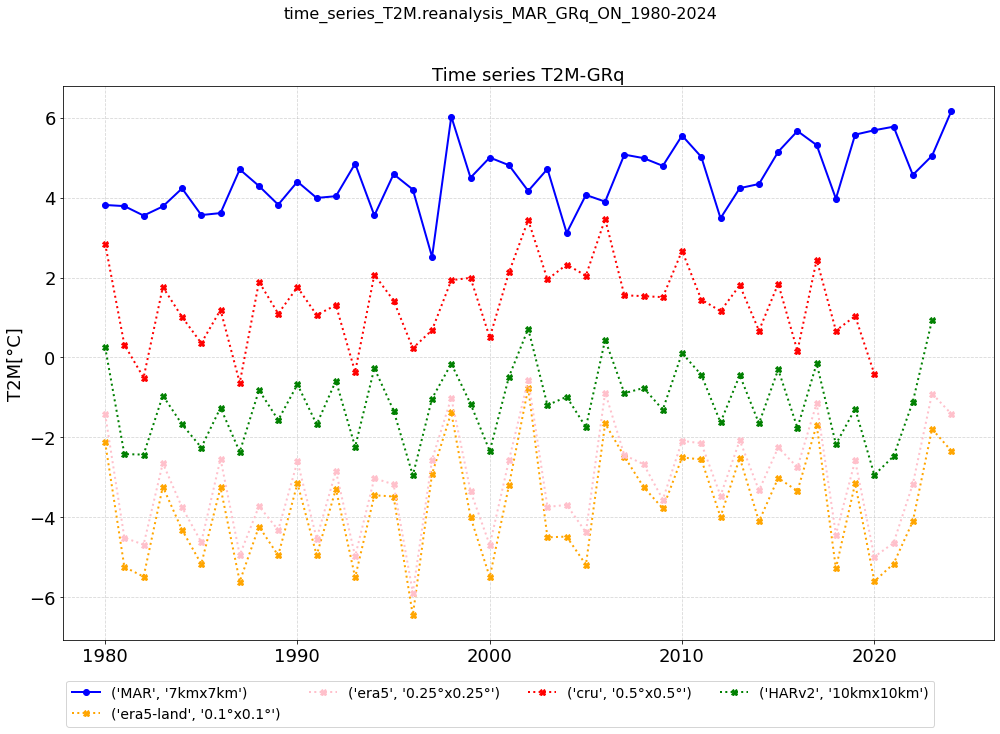

/home/santolam/RECAP/figures/time_series_T2M.reanalysis_MAR_GRq_ON_1980-2024.png
[4.490780830383301, -3.737774610519409, -3.14992618560791, 1.3512861728668213, -1.169225811958313]
[0.7985340356826782, 1.3360419273376465, 1.2927106618881226, 0.982750415802002, 0.9498577117919922]


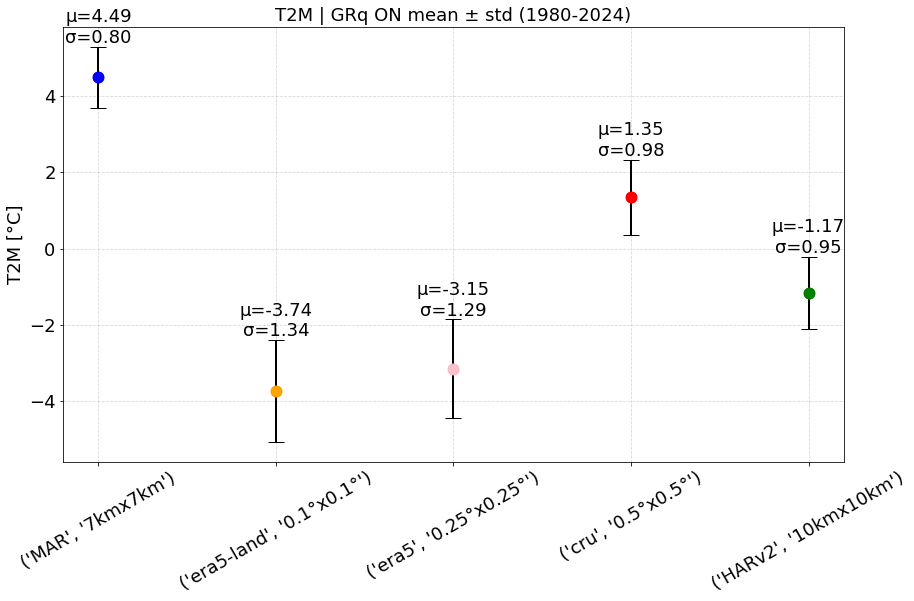

/home/santolam/RECAP/figures/mean_stddev_T2M.reanalysis_MAR_GRq_ON_1980-2024.png


In [34]:
season=seasonList[3]
print(season)
field1_season = field1_season_all.sel(season=season)
field3_season = field3_season_all.sel(season=season)
field4_season = field4_season_all.sel(season=season)
field5_season = field5_season_all.sel(season=season)
#field6_season = field6_season_all.sel(season=season)
field7_season = field7_season_all.sel(season=season)

# Then apply it like this:
ts_mean_vals_field1 = field1_season.mean(dim=['X', 'Y'])
ts_mean_vals_field3 = field3_season.mean(dim= ['lon', 'lat'])
ts_mean_vals_field4= field4_season.mean(dim=['lon', 'lat'])
ts_mean_vals_field5= field5_season.mean(dim= ['lon', 'lat'])
#ts_mean_vals_field6= field6_season.mean(dim=['lon', 'lat'])
ts_mean_vals_field7 = field7_season.mean(dim=  ['south_north', 'west_east'])

colorList=['b','orange', 'pink', 'red', 'green','black']
markerList=['o','X','X','X','X','X','X']#

plotname=f'time_series_{var}.reanalysis_MAR_{domainM}_{season}_{str(iyr)}-{str(fyr)}'

colors = colorList


fig, ax= plt.subplots(figsize=(14, 10), sharex=False, sharey=False)

# Plot one line per dataset
ax.plot(ts_mean_vals_field1.year, ts_mean_vals_field1.values, 'o', linestyle='-',label=nameList[0], color=colors[0], linewidth=2)
ax.plot(ts_mean_vals_field3.year, ts_mean_vals_field3.values,marker=markerList[1], linestyle=':',label=nameList[1], color=colors[1], linewidth=2)
ax.plot(ts_mean_vals_field4.year, ts_mean_vals_field4.values,marker=markerList[2],linestyle=':',label=nameList[2], color=colors[2], linewidth=2)
ax.plot(ts_mean_vals_field5.year,ts_mean_vals_field5.values, marker=markerList[3],linestyle=':',label=nameList[3], color=colors[3], linewidth=2)
#ax.plot(ts_mean_vals_field6.year ,ts_mean_vals_field6.values,marker=markerList[4],linestyle='-',label=nameList[4], color=colors[4], linewidth=2)    
ax.plot(ts_mean_vals_field7.year,ts_mean_vals_field7.values, marker=markerList[5],linestyle=':',label=nameList[4], color=colors[4], linewidth=2)

ax.set_title(f'Time series {var}-{domainM}', fontsize=18)
#ax.set_xticks(months)
ax.set_ylabel(f'{var}[{units}]', fontsize=18)
#years=ac_mean_vals_field1[0].year.values
#xticks = years[::2]
ax.tick_params(axis='y', labelsize=18)
ax.tick_params(axis='x', labelsize=18)

ax.grid(True, linestyle='--', alpha=0.5)

# Axis labels and legend
fig.suptitle(plotname, fontsize=16)
#fig.supxlabel('Month', fontsize=14)
#fig.supylabel('Snow Height [m]', fontsize=14)

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc='lower center',
    bbox_to_anchor=(0.5, -0.03),
    ncol=4,
    fontsize=14,
    frameon=True
)

# Adjust layout and save with full legend
plt.tight_layout(rect=[0, 0.05, 1, 0.95])
#plt.savefig(plotsDir + 'monthly_snowheight_by_elevation.png', , dpi=300)

# Save figure (including legend outside)
plt.savefig(plotsDir+plotname+'.png', bbox_inches='tight')
plt.show()
print(plotsDir+plotname+'.png')


datasets = [
    ts_mean_vals_field1,
    ts_mean_vals_field3,
    ts_mean_vals_field4,
    ts_mean_vals_field5,
    #ts_mean_vals_field6,
    ts_mean_vals_field7,
]

dataset_names = nameList  # same order
colors = colorList

means = [ds.mean(dim='year').values.item() for ds in datasets]
stds  = [ds.std(dim='year').values.item() for ds in datasets]
print(means)
print(stds)
plotname=f'mean_stddev_{var}.reanalysis_MAR_{domainM}_{season}_{str(iyr)}-{str(fyr)}'

fig, ax = plt.subplots(figsize=(14, 8))

x = np.arange(len(dataset_names))

ax.errorbar(
    x, means, yerr=stds,
    fmt='o',
    capsize=8,
    markersize=10,
    linewidth=2,
    color='black'
)

# Color individual points
for xi, mu, color in zip(x, means, colors):
    ax.scatter(xi, mu, color=color, s=120, zorder=3)

ax.set_xticks(x)
ax.set_xticklabels(dataset_names, rotation=30,fontsize=18)
ax.set_ylabel(f'{var} [{units}]',fontsize=18)
ax.tick_params(axis='y', labelsize=18)
ax.tick_params(axis='x', labelsize=18)
#ax.set_ylim(-1,6)
ax.set_title(f'{var} | {domainM} {season} mean ± std ({iyr}-{fyr})',fontsize=18)
ax.grid(True, linestyle='--', alpha=0.5)

# Annotate
for xi, mu, sigma in zip(x, means, stds):
    ax.text(
        xi, mu + sigma,
        f'μ={mu:.2f}\nσ={sigma:.2f}',
        ha='center',
        va='bottom',
        fontsize=18
    )

# Save figure (including legend outside)
plt.savefig(plotsDir+plotname+'.png', bbox_inches='tight')
plt.show()
print(plotsDir+plotname+'.png')

ANN


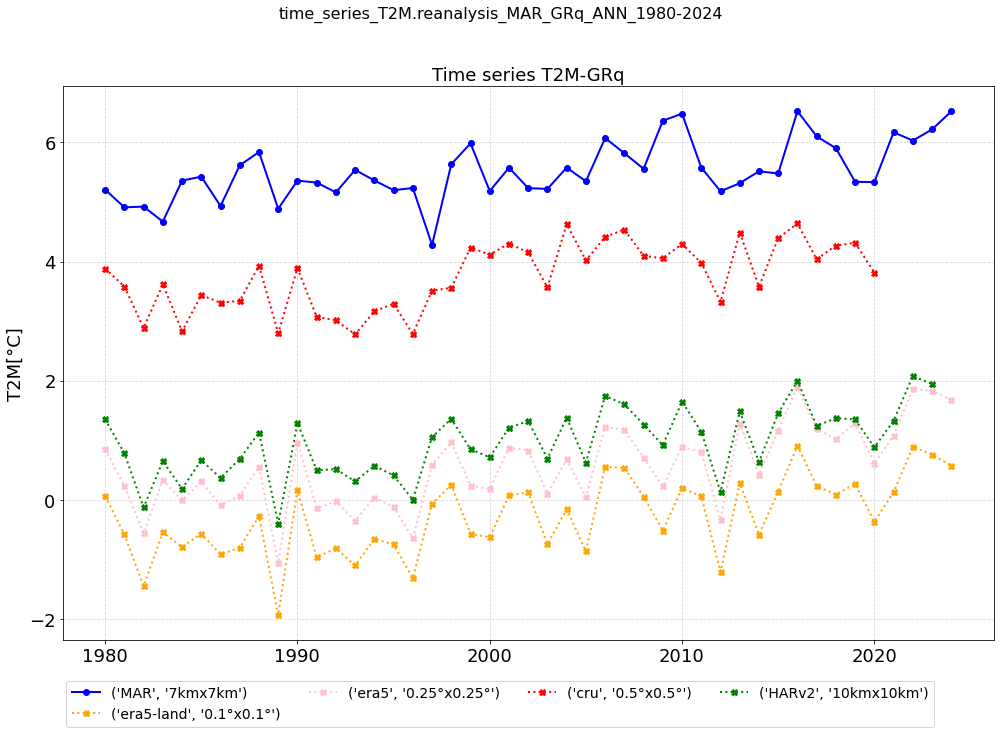

/home/santolam/RECAP/figures/time_series_T2M.reanalysis_MAR_GRq_ANN_1980-2024.png
[5.522611618041992, -0.28294193744659424, 0.5543408989906311, 3.755478620529175, 0.9635873436927795]
[0.4911510944366455, 0.6435495018959045, 0.6801062226295471, 0.5537249445915222, 0.570813775062561]


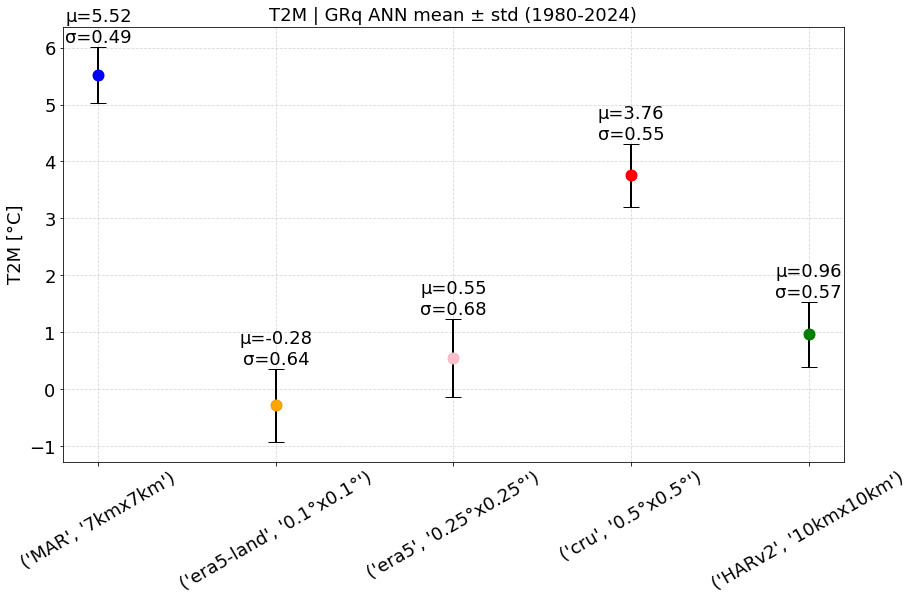

/home/santolam/RECAP/figures/mean_stddev_T2M.reanalysis_MAR_GRq_ANN_1980-2024.png


In [32]:
season=seasonList[4]
print(season)
field1_season = field1_season_all.sel(season=season)
field3_season = field3_season_all.sel(season=season)
field4_season = field4_season_all.sel(season=season)
field5_season = field5_season_all.sel(season=season)
#field6_season = field6_season_all.sel(season=season)
field7_season = field7_season_all.sel(season=season)

# Then apply it like this:
ts_mean_vals_field1 = field1_season.mean(dim=['X', 'Y'])
ts_mean_vals_field3 = field3_season.mean(dim= ['lon', 'lat'])
ts_mean_vals_field4= field4_season.mean(dim=['lon', 'lat'])
ts_mean_vals_field5= field5_season.mean(dim= ['lon', 'lat'])
#ts_mean_vals_field6= field6_season.mean(dim=['lon', 'lat'])
ts_mean_vals_field7 = field7_season.mean(dim=  ['south_north', 'west_east'])

colorList=['b','orange', 'pink', 'red', 'green','black']
markerList=['o','X','X','X','X','X','X']#

plotname=f'time_series_{var}.reanalysis_MAR_{domainM}_{season}_{str(iyr)}-{str(fyr)}'

colors = colorList


fig, ax= plt.subplots(figsize=(14, 10), sharex=False, sharey=False)

# Plot one line per dataset
ax.plot(ts_mean_vals_field1.year, ts_mean_vals_field1.values, 'o', linestyle='-',label=nameList[0], color=colors[0], linewidth=2)
ax.plot(ts_mean_vals_field3.year, ts_mean_vals_field3.values,marker=markerList[1], linestyle=':',label=nameList[1], color=colors[1], linewidth=2)
ax.plot(ts_mean_vals_field4.year, ts_mean_vals_field4.values,marker=markerList[2],linestyle=':',label=nameList[2], color=colors[2], linewidth=2)
ax.plot(ts_mean_vals_field5.year,ts_mean_vals_field5.values, marker=markerList[3],linestyle=':',label=nameList[3], color=colors[3], linewidth=2)
#ax.plot(ts_mean_vals_field6.year ,ts_mean_vals_field6.values,marker=markerList[4],linestyle='-',label=nameList[4], color=colors[4], linewidth=2)    
ax.plot(ts_mean_vals_field7.year,ts_mean_vals_field7.values, marker=markerList[5],linestyle=':',label=nameList[4], color=colors[4], linewidth=2)

ax.set_title(f'Time series {var}-{domainM}', fontsize=18)
#ax.set_xticks(months)
ax.set_ylabel(f'{var}[{units}]', fontsize=18)
#years=ac_mean_vals_field1[0].year.values
#xticks = years[::2]
ax.tick_params(axis='y', labelsize=18)
ax.tick_params(axis='x', labelsize=18)

ax.grid(True, linestyle='--', alpha=0.5)

# Axis labels and legend
fig.suptitle(plotname, fontsize=16)
#fig.supxlabel('Month', fontsize=14)
#fig.supylabel('Snow Height [m]', fontsize=14)

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc='lower center',
    bbox_to_anchor=(0.5, -0.03),
    ncol=4,
    fontsize=14,
    frameon=True
)

# Adjust layout and save with full legend
plt.tight_layout(rect=[0, 0.05, 1, 0.95])
#plt.savefig(plotsDir + 'monthly_snowheight_by_elevation.png', , dpi=300)

# Save figure (including legend outside)
plt.savefig(plotsDir+plotname+'.png', bbox_inches='tight')
plt.show()
print(plotsDir+plotname+'.png')


datasets = [
    ts_mean_vals_field1,
    ts_mean_vals_field3,
    ts_mean_vals_field4,
    ts_mean_vals_field5,
    #ts_mean_vals_field6,
    ts_mean_vals_field7,
]

dataset_names = nameList  # same order
colors = colorList

means = [ds.mean(dim='year').values.item() for ds in datasets]
stds  = [ds.std(dim='year').values.item() for ds in datasets]
print(means)
print(stds)
plotname=f'mean_stddev_{var}.reanalysis_MAR_{domainM}_{season}_{str(iyr)}-{str(fyr)}'

fig, ax = plt.subplots(figsize=(14, 8))

x = np.arange(len(dataset_names))

ax.errorbar(
    x, means, yerr=stds,
    fmt='o',
    capsize=8,
    markersize=10,
    linewidth=2,
    color='black'
)

# Color individual points
for xi, mu, color in zip(x, means, colors):
    ax.scatter(xi, mu, color=color, s=120, zorder=3)

ax.set_xticks(x)
ax.set_xticklabels(dataset_names, rotation=30,fontsize=18)
ax.set_ylabel(f'{var} [{units}]',fontsize=18)
ax.tick_params(axis='y', labelsize=18)
ax.tick_params(axis='x', labelsize=18)
#ax.set_ylim(0,70)
ax.set_title(f'{var} | {domainM} {season} mean ± std ({iyr}-{fyr})',fontsize=18)
ax.grid(True, linestyle='--', alpha=0.5)

# Annotate
for xi, mu, sigma in zip(x, means, stds):
    ax.text(
        xi, mu + sigma,
        f'μ={mu:.2f}\nσ={sigma:.2f}',
        ha='center',
        va='bottom',
        fontsize=18
    )

# Save figure (including legend outside)
plt.savefig(plotsDir+plotname+'.png', bbox_inches='tight')
plt.show()
print(plotsDir+plotname+'.png')